# 02 · Resultados para el artículo

Agrega las corridas y genera tablas (CSV + LaTeX booktabs) y figuras (PDF + PNG a 300 dpi, ancho de columna IEEE).

- **Colab:** monta Google Drive y lee `IA_ProyectoFinal_RoCoLe/results`.
- **Local:** define `ROCOLE_RESULTS_ROOT` (por defecto, `results/` del repositorio) y `ROCOLE_DATA_ROOT` (para la figura de mapas).

Salidas en el repositorio: `results/tablas/*.{csv,tex}` (incluye los agregados runs, summary, bootstrap y comparisons), `results/figuras/*.{pdf,png}` y copia de los JSON en `results/runs/` (sin pesos ni mapas).

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Rosa-SDev/roya-cafe-cbam-vs-deit.git"
SHARED_DIR = Path("/content/drive/MyDrive/IA_ProyectoFinal_RoCoLe")  # carpeta de Drive con los resultados (solo Colab)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = Path("/content/codigo")
    if not REPO.exists():
        subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))
print("Repositorio:", REPO, "| commit:", subprocess.run(["git", "rev-parse", "--short", "HEAD"],
      capture_output=True, text=True).stdout.strip())

Repositorio: R:\UNI\Semestre_6\IA\Tercer_Corte - ProyectoFinal\codigo | commit: 878c09e


In [2]:
import shutil
import pandas as pd
from src import report
from src.aggregate import aggregate, load_runs
from src.runs import all_runs, result_path

RESULTS_ROOT = SHARED_DIR / "results" if IN_COLAB else Path(os.environ.get("ROCOLE_RESULTS_ROOT", REPO / "results"))
DATA_ROOT = Path("/content/data") if IN_COLAB else Path(os.environ.get("ROCOLE_DATA_ROOT", REPO / "data" / "cache"))
FIG_DIR, TAB_DIR = REPO / "results" / "figuras", REPO / "results" / "tablas"

expected = all_runs()
missing = [r["name"] + " (" + r["experiment"] + ")" for r in expected if not result_path(RESULTS_ROOT, r).exists()]
print(f"Corridas encontradas: {len(expected) - len(missing)} de {len(expected)}")
if missing:
    print("Faltan:", *missing[:20], "..." if len(missing) > 20 else "", sep="\n  ")

Corridas encontradas: 69 de 69


In [3]:
# Copia los JSON al repositorio (versionables; los .npz y .pt no se suben)
if RESULTS_ROOT.resolve() != (REPO / "results").resolve():
    for path in (RESULTS_ROOT / "runs").glob("E*/*.json"):
        dest = REPO / "results" / "runs" / path.parent.name / path.name
        dest.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, dest)

tables = aggregate(RESULTS_ROOT, TAB_DIR, reps=2000)
summary, boot, comp = tables["summary"], tables["bootstrap"], tables["comparisons"]
runs = load_runs(RESULTS_ROOT)
display(summary[["experiment", "config", "fraction", "n_seeds", "macro_f1_mean", "macro_f1_std", "accuracy_mean"]])

69 corridas agregadas -> R:\UNI\Semestre_6\IA\Tercer_Corte - ProyectoFinal\codigo\results\tablas


,experiment,config,fraction,n_seeds,macro_f1_mean,macro_f1_std,accuracy_mean
0,E1,cnn_cbam_scratch,1.00,5,0.499561,0.016849,0.706780
1,E1,cnn_scratch,1.00,5,0.476284,0.043546,0.688983
2,E1,deit_pre,1.00,5,0.516687,0.051473,0.743220
3,E1,deit_scratch,1.00,5,0.275062,0.024049,0.418644
4,E1,mbv2_cbam_pre,1.00,5,0.480292,0.035000,0.742373
5,E1,mbv2_pre,1.00,5,0.502426,0.013613,0.747458
6,E2,cnn_cbam_channel_scratch,1.00,5,0.491102,0.033420,0.706780
7,E2,cnn_cbam_last2_scratch,1.00,5,0.530707,0.057498,0.709322
8,E2,cnn_cbam_spatial_scratch,1.00,5,0.529458,0.030611,0.726271
9,E3,cnn_cbam_scratch,0.25,2,0.451294,0.004822,0.658898


## Hipótesis: diferencias pareadas (bootstrap por planta, IC95)

`point` es la diferencia de medias entre semillas (A − B); `p_le_0` es la fracción de réplicas bootstrap con diferencia ≤ 0 (cercana a 0 respalda A > B).

In [4]:
pd.set_option("display.max_colwidth", 60)
display(comp[comp.metric.isin(["macro_f1"]) | comp.hypothesis.eq("H4")].round(4))

,comparison,hypothesis,metric,a,b,n_a,n_b,point,ci_low,ci_high,p_le_0
0,cnn_cbam - cnn (desde cero),H1,macro_f1,E1/cnn_cbam_scratch/1.0,E1/cnn_scratch/1.0,5,5,0.0233,-0.0351,0.0832,0.2010
3,mbv2_cbam - mbv2 (preentrenado),H1,macro_f1,E1/mbv2_cbam_pre/1.0,E1/mbv2_pre/1.0,5,5,-0.0221,-0.0673,0.0251,0.8225
6,deit - cnn (desde cero),H2,macro_f1,E1/deit_scratch/1.0,E1/cnn_scratch/1.0,5,5,-0.2012,-0.2857,-0.1129,1.0000
9,deit - cnn_cbam (desde cero),H2,macro_f1,E1/deit_scratch/1.0,E1/cnn_cbam_scratch/1.0,5,5,-0.2245,-0.2856,-0.1564,1.0000
12,deit - mbv2 (preentrenado),H2,macro_f1,E1/deit_pre/1.0,E1/mbv2_pre/1.0,5,5,0.0143,-0.0407,0.0664,0.3050
15,deit - mbv2_cbam (preentrenado),H2,macro_f1,E1/deit_pre/1.0,E1/mbv2_cbam_pre/1.0,5,5,0.0364,-0.0256,0.0925,0.1245
18,deit_pre - deit_scratch,H2,macro_f1,E1/deit_pre/1.0,E1/deit_scratch/1.0,5,5,0.2416,0.1787,0.2984,0.0000
21,cbam_channel - cnn,E2,macro_f1,E2/cnn_cbam_channel_scratch/1.0,E1/cnn_scratch/1.0,5,5,0.0148,-0.0384,0.0766,0.2605
24,cbam_spatial - cnn,E2,macro_f1,E2/cnn_cbam_spatial_scratch/1.0,E1/cnn_scratch/1.0,5,5,0.0532,-0.0016,0.1160,0.0320
27,cbam_last2 - cnn,E2,macro_f1,E2/cnn_cbam_last2_scratch/1.0,E1/cnn_scratch/1.0,5,5,0.0544,0.0010,0.1106,0.0240


## Tablas

In [5]:
report.setup_style()
t1 = report.table_e1(summary, boot)
report.save_table(t1, TAB_DIR, "tabla_e1", "Resultados en prueba (E1): media $\\pm$ desviación entre 5 semillas e IC95 por bootstrap por planta.", "tab:e1")
t2 = report.table_e2(summary, boot)
report.save_table(t2, TAB_DIR, "tabla_e2_ablacion", "Ablación de CBAM en la CNN entrenada desde cero (E2).", "tab:e2")
# Tiempos: solo E1 semillas 0-3 en la RTX 3050 (la semilla 4 y E2 corrieron en T4).
# Las métricas de clasificación (t1, t2) sí usan las 5 semillas, sin importar la GPU.
t3 = report.table_train_times(tables["runs"])
report.save_table(t3, TAB_DIR, "tabla_parametros_tiempos", "Parámetros y tiempo de entrenamiento en una RTX 3050 6 GB Laptop (E1, semillas 0-3; media $\\pm$ desviación). Época estable: mediana de segundos por época sin la primera.", "tab:params")
comp.round(4).to_csv(TAB_DIR / "comparaciones_hipotesis.csv", index=False)
display(t1); display(t2); display(t3)
print("GPU por corrida:"); display(tables["runs"].groupby(["experiment", "gpu"]).size().rename("corridas").to_frame())
inf_csv = TAB_DIR / "inferencia_rtx3050.csv"
if inf_csv.exists():  # lo genera: python -m src.bench_inference
    display(report.table_inference(pd.read_csv(inf_csv)))
else:
    print("Falta el benchmark de inferencia: python -m src.bench_inference")

,Modelo,Parámetros (M),Exactitud,F1 macro,IC95 F1 macro,F1 sana/enferma,n
0,CNN (cero),1.17,0.689 $\pm$ 0.025,0.476 $\pm$ 0.044,"[0.392, 0.549]",0.889 $\pm$ 0.038,5
1,CNN+CBAM (cero),1.19,0.707 $\pm$ 0.019,0.500 $\pm$ 0.017,"[0.425, 0.560]",0.918 $\pm$ 0.023,5
2,DeiT-Ti (cero),5.53,0.419 $\pm$ 0.023,0.275 $\pm$ 0.024,"[0.219, 0.332]",0.706 $\pm$ 0.017,5
3,MBV2 (pre),2.23,0.747 $\pm$ 0.011,0.502 $\pm$ 0.014,"[0.430, 0.561]",0.929 $\pm$ 0.006,5
4,MBV2+CBAM (pre),2.24,0.742 $\pm$ 0.015,0.480 $\pm$ 0.035,"[0.421, 0.534]",0.941 $\pm$ 0.007,5
5,DeiT-Ti (pre),5.53,0.743 $\pm$ 0.026,0.517 $\pm$ 0.051,"[0.447, 0.571]",0.926 $\pm$ 0.023,5


,Variante,Parámetros CBAM,Exactitud,F1 macro,IC95 F1 macro,n
0,Sin CBAM,0,0.689 $\pm$ 0.025,0.476 $\pm$ 0.044,"[0.392, 0.549]",5
1,CBAM canal+espacial (4 bloques),"11,782",0.707 $\pm$ 0.019,0.500 $\pm$ 0.017,"[0.425, 0.560]",5
2,Solo canal (4 bloques),"11,390",0.707 $\pm$ 0.018,0.491 $\pm$ 0.033,"[0.409, 0.567]",5
3,Solo espacial (4 bloques),392,0.726 $\pm$ 0.024,0.529 $\pm$ 0.031,"[0.438, 0.605]",5
4,Canal+espacial (bloques 3-4),"10,844",0.709 $\pm$ 0.045,0.531 $\pm$ 0.057,"[0.442, 0.600]",5


,Modelo,Parámetros,Parámetros CBAM,Entrenamiento (min),Época estable (s),Épocas,Semillas
0,CNN (cero),"1,174,758",0,4.7 $\pm$ 0.7,5.5 $\pm$ 0.1,48 $\pm$ 9,"0,1,2,3"
1,CNN+CBAM (cero),"1,186,540","11,782",8.9 $\pm$ 1.4,9.6 $\pm$ 0.2,54 $\pm$ 8,"0,1,2,3"
2,DeiT-Ti (cero),"5,525,574",0,4.6 $\pm$ 0.2,4.4 $\pm$ 0.5,60 $\pm$ 1,"0,1,2,3"
3,MBV2 (pre),"2,231,558",0,2.7 $\pm$ 0.3,4.8 $\pm$ 0.4,29 $\pm$ 2,"0,1,2,3"
4,MBV2+CBAM (pre),"2,237,316","5,758",2.8 $\pm$ 0.1,5.3 $\pm$ 0.4,28 $\pm$ 3,"0,1,2,3"
5,DeiT-Ti (pre),"5,525,574",0,2.5 $\pm$ 0.4,4.6 $\pm$ 0.3,28 $\pm$ 3,"0,1,2,3"


GPU por corrida:


corridas
experiment gpu                                             
E1         NVIDIA GeForce RTX 3050 6GB Laptop GPU        24
           Tesla T4                                       6
E2         Tesla T4                                      15
E3         NVIDIA GeForce RTX 3050 6GB Laptop GPU        24

,Modelo,Latencia FP32 (ms),Throughput FP32 (img/s),Latencia FP16 (ms),Throughput FP16 (img/s)
0,CNN (cero),2.42,517,2.79,874
1,CNN+CBAM (cero),5.56,363,7.21,623
2,DeiT-Ti (cero),10.84,789,13.56,1625
3,MBV2 (pre),9.89,715,12.94,1316
4,MBV2+CBAM (pre),13.50,696,19.76,1243
5,DeiT-Ti (pre),10.08,789,13.45,1624


## Figuras

In [6]:
report.fig_f1_bars(summary, FIG_DIR)
report.fig_data_curves(summary, FIG_DIR)
report.fig_confusions(runs, summary, FIG_DIR)
report.fig_recall_per_class(summary, FIG_DIR)
report.fig_in_leaf(summary, FIG_DIR)
if (DATA_ROOT / "rocole_256.npz").exists():
    from src.data import load_cache
    cache = load_cache(DATA_ROOT)
    report.fig_attention_examples(RESULTS_ROOT, runs, cache["images"], cache["names"], FIG_DIR)
else:
    print("Sin caché de imágenes: se omite la figura de mapas de atención")
print(sorted(p.name for p in FIG_DIR.glob("*.pdf")))

['curvas_datos_f1.pdf', 'ejemplos_mapas_atencion.pdf', 'f1_macro_por_configuracion.pdf', 'fraccion_atencion_hoja.pdf', 'matrices_confusion_mejor_por_familia.pdf', 'sensibilidad_por_clase.pdf']


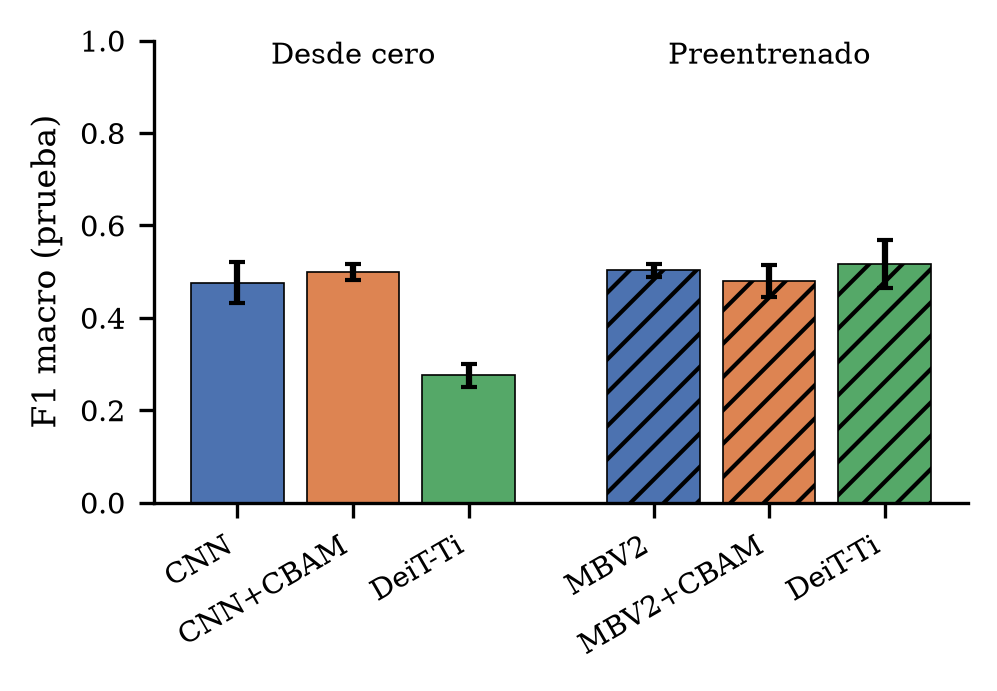

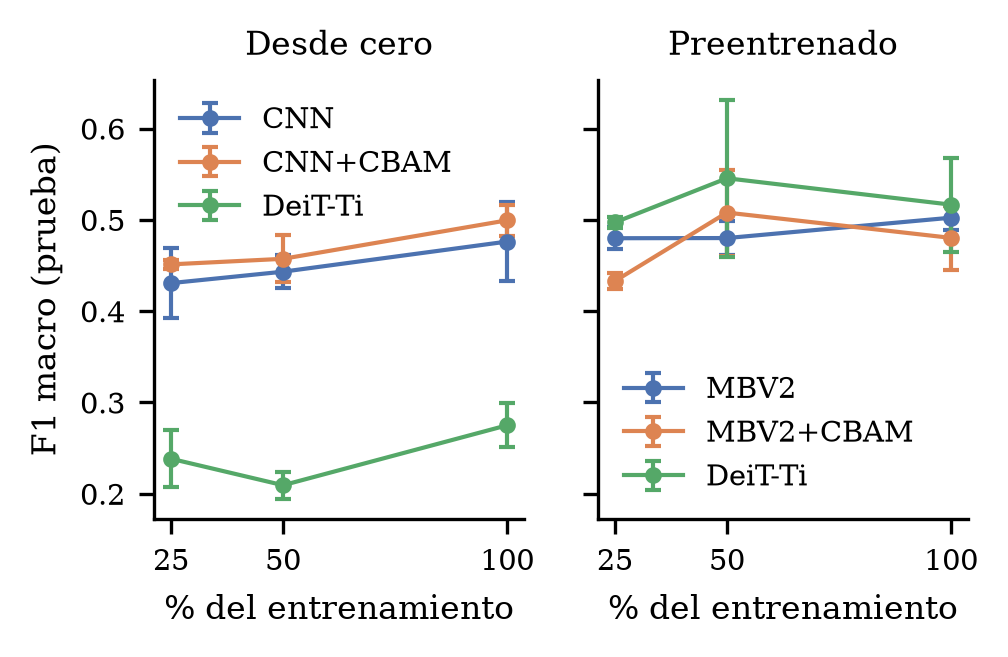

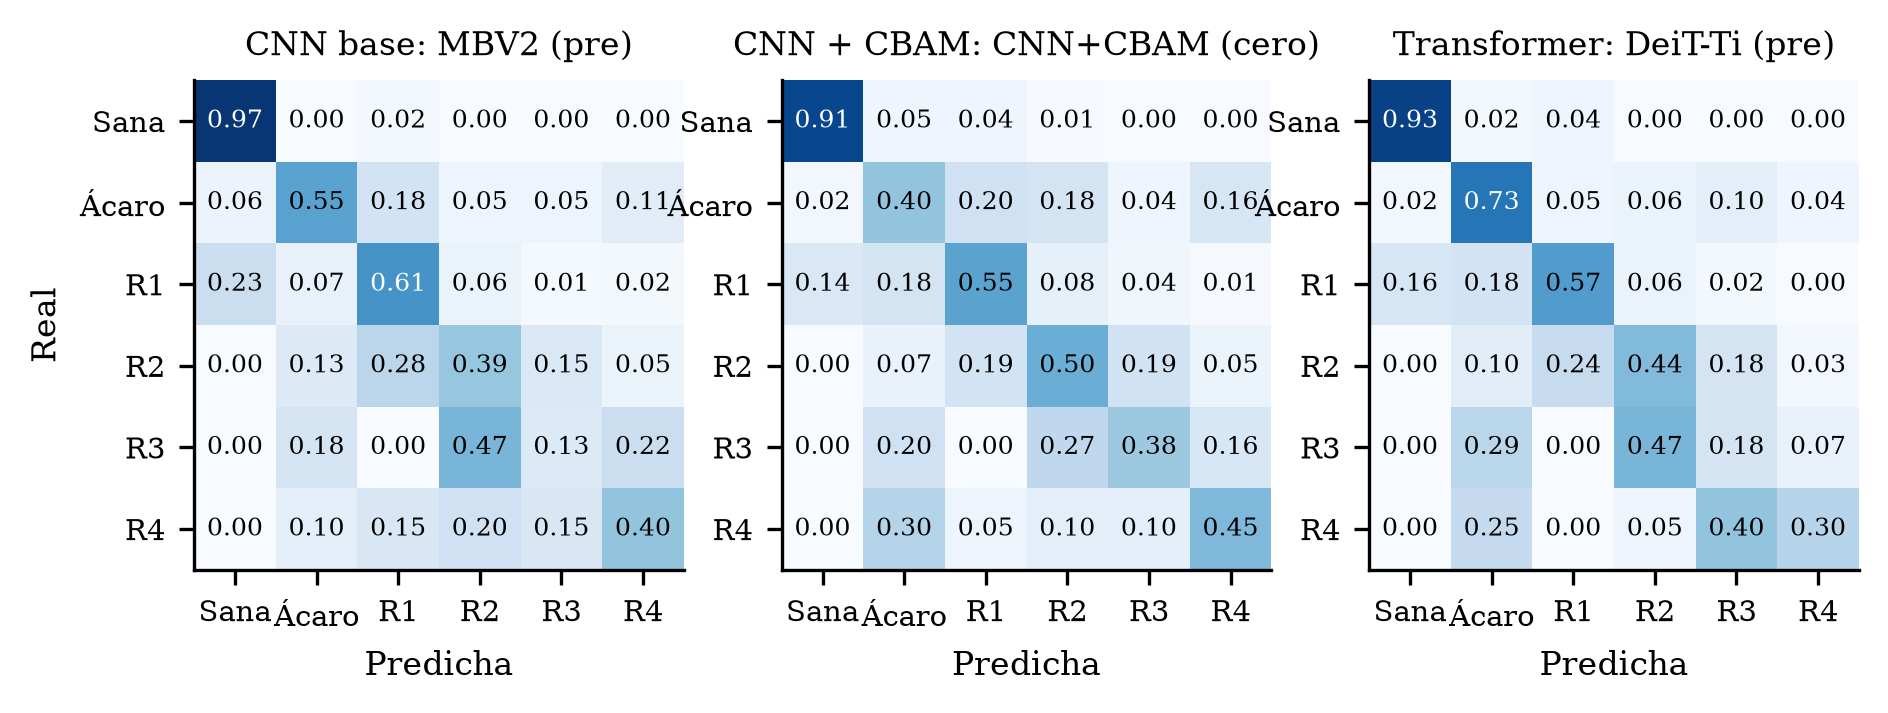

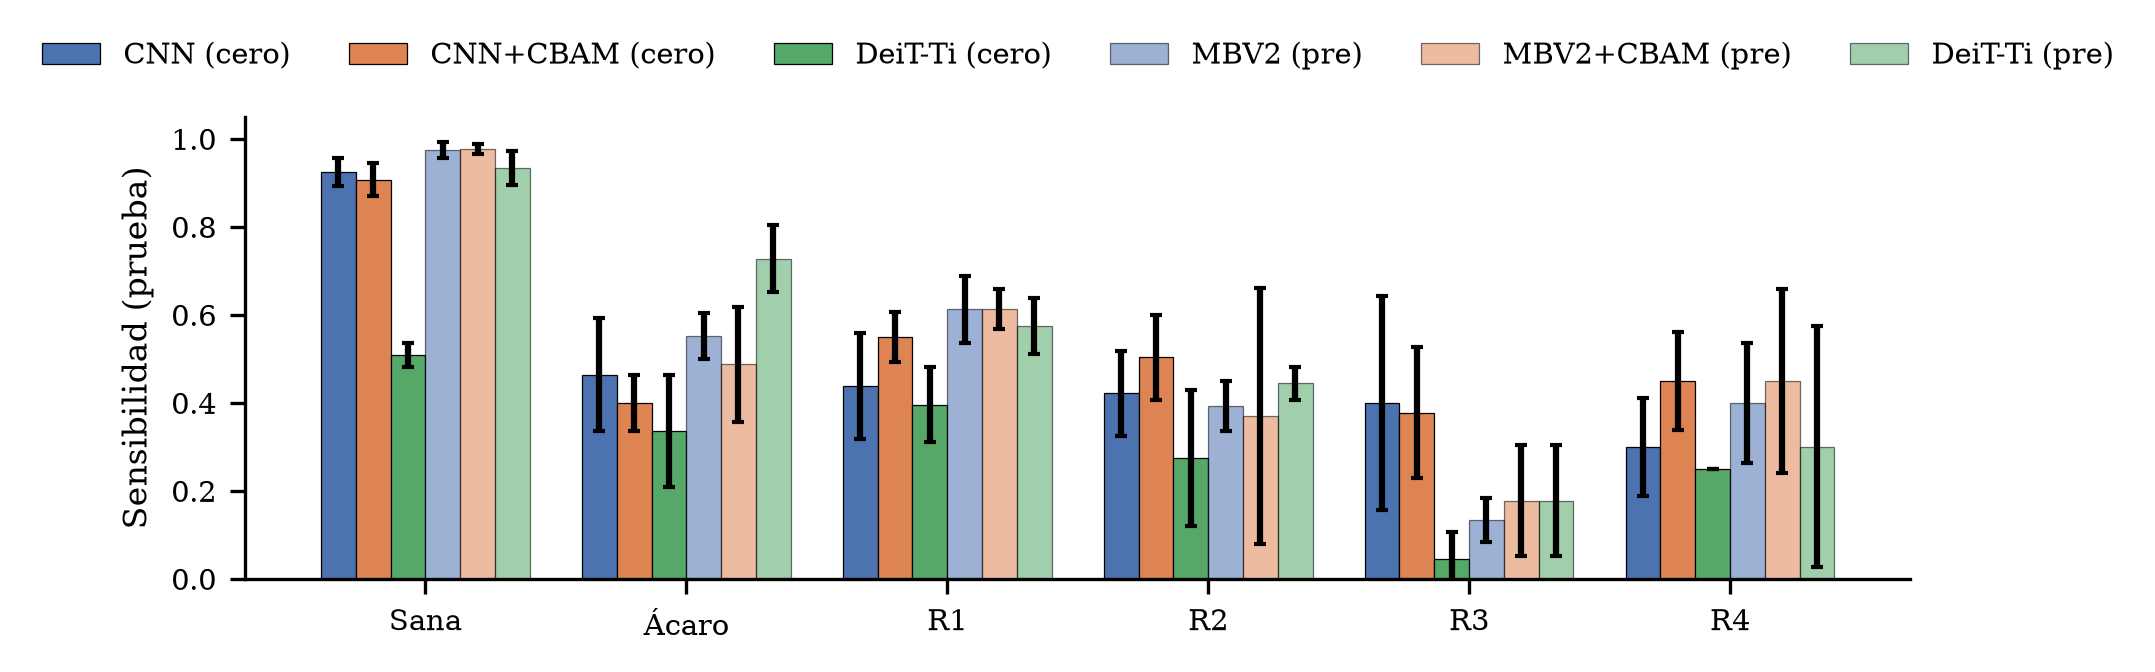

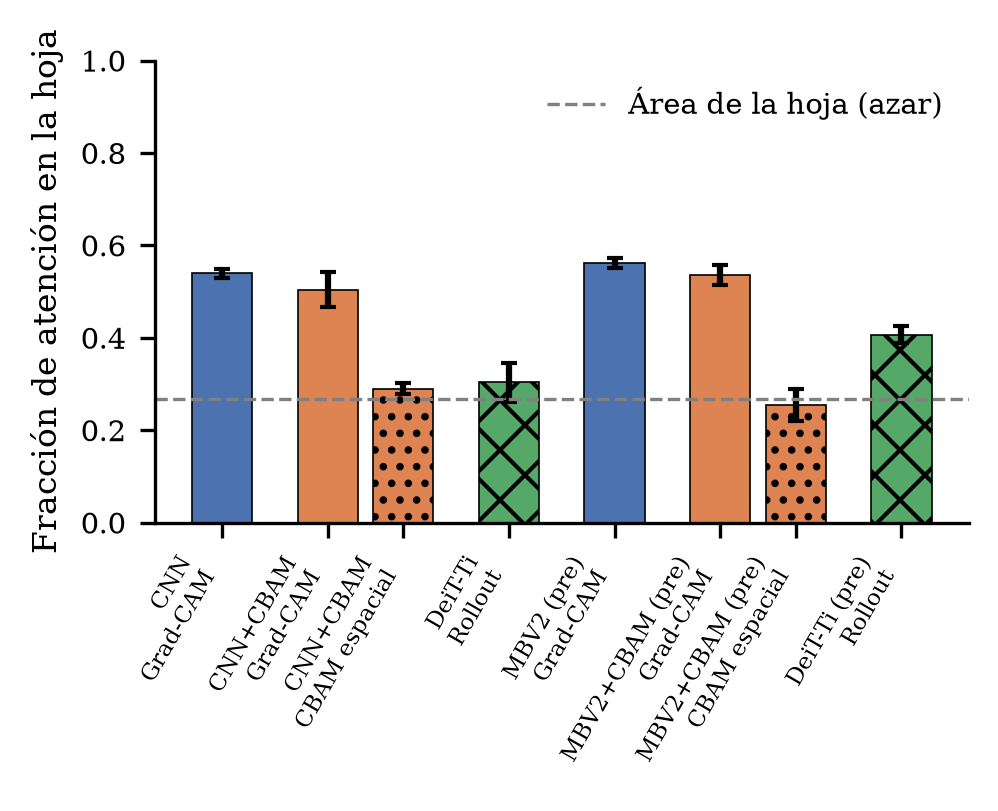

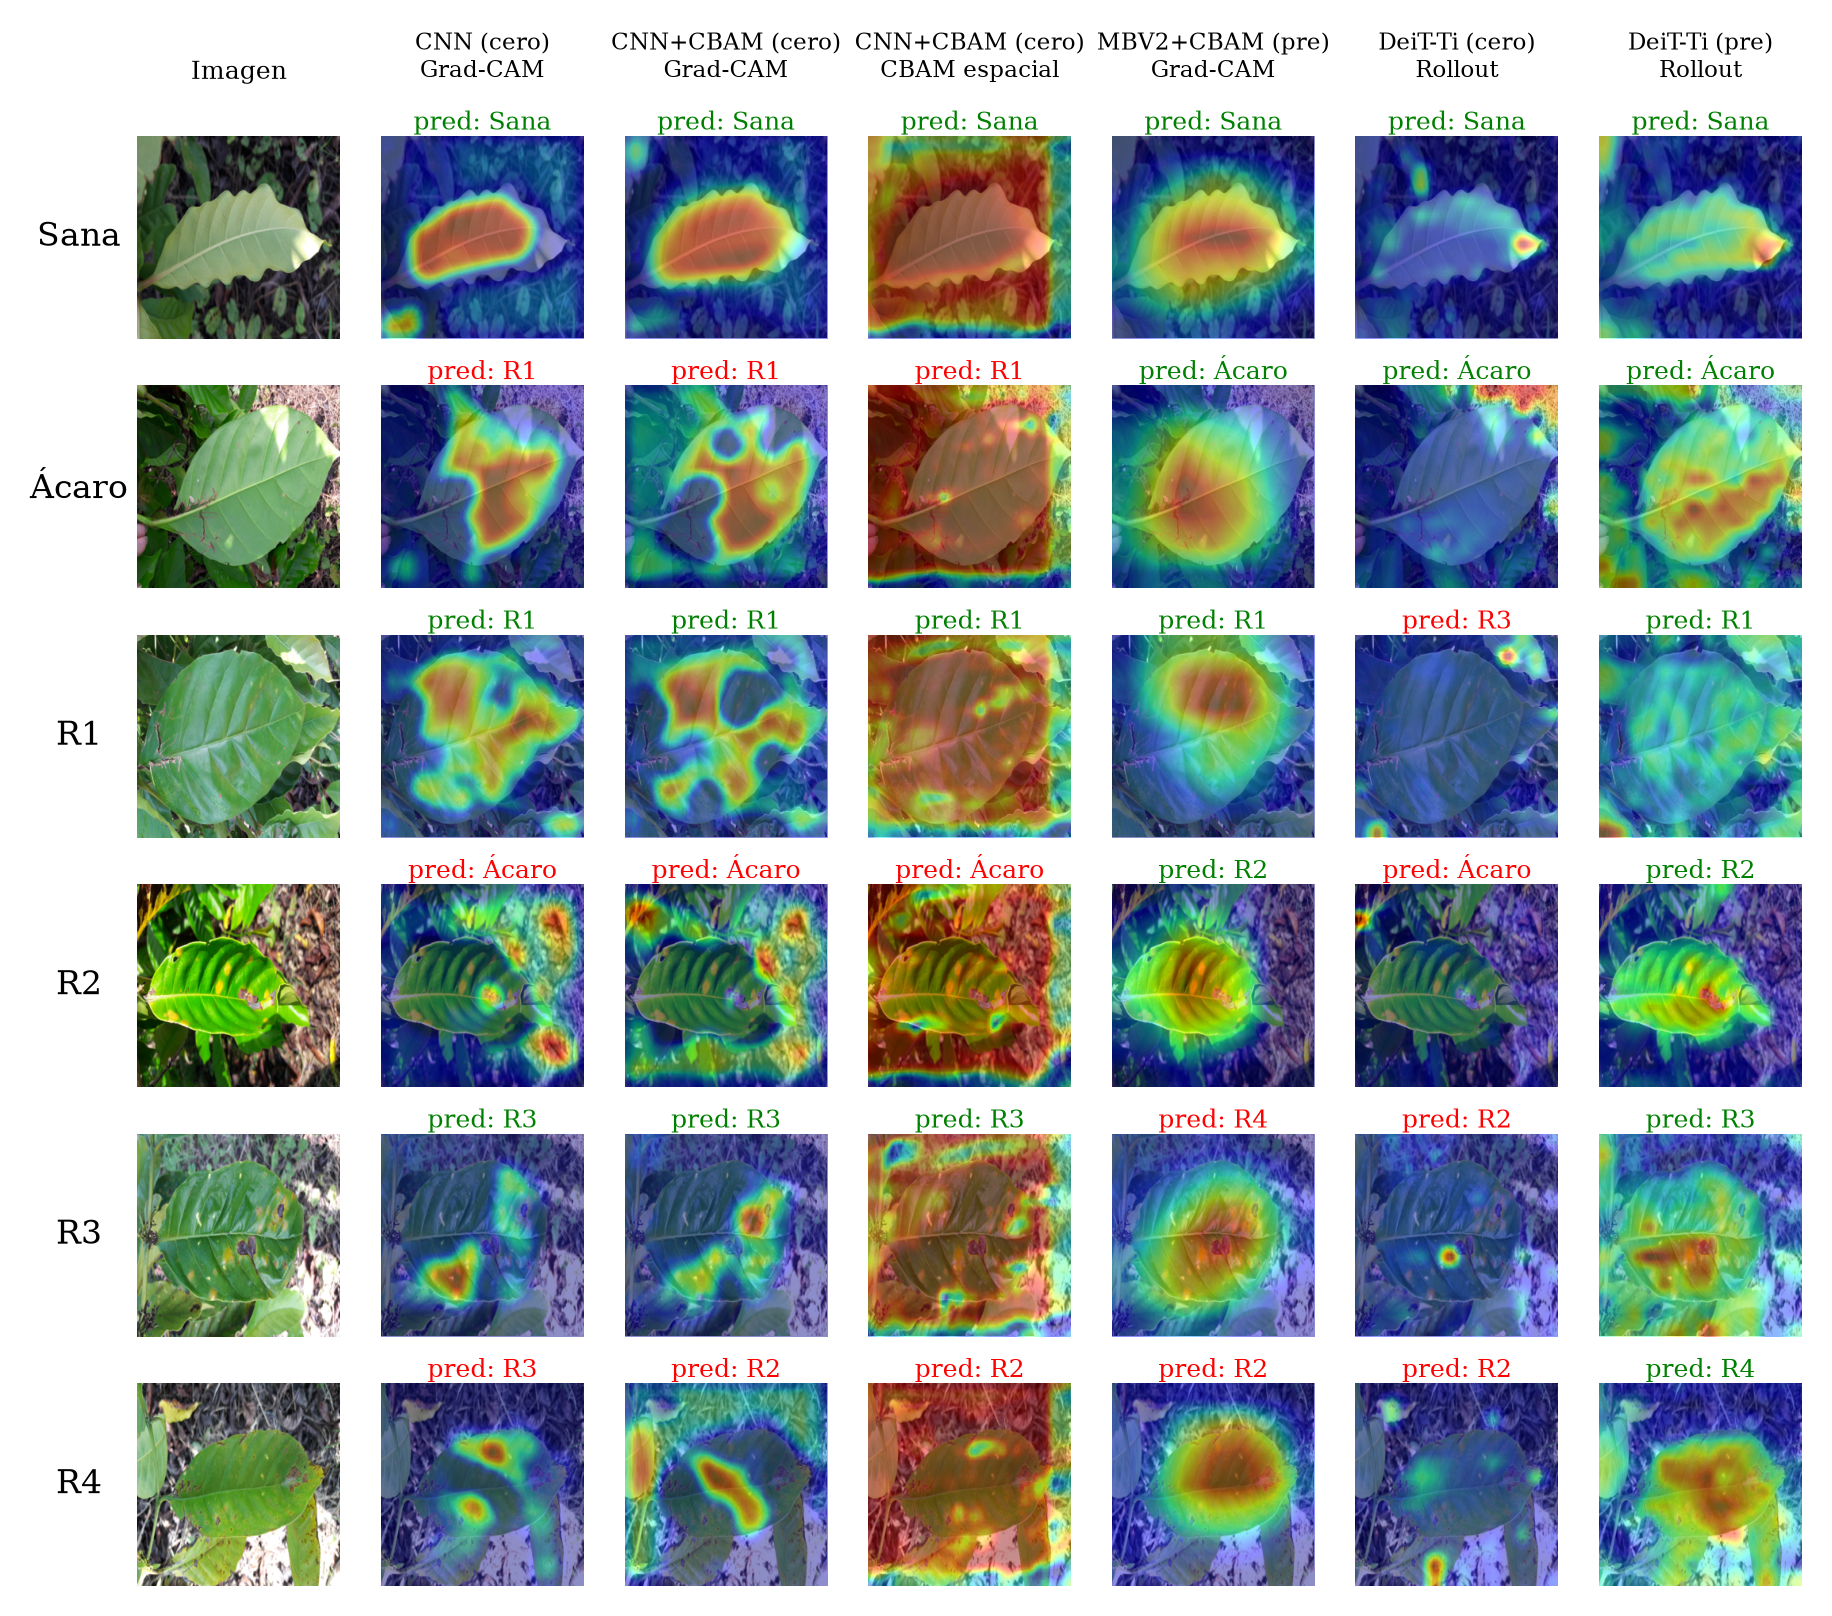

In [7]:
from IPython.display import Image, display as show
for name in ["f1_macro_por_configuracion", "curvas_datos_f1", "matrices_confusion_mejor_por_familia",
             "sensibilidad_por_clase", "fraccion_atencion_hoja", "ejemplos_mapas_atencion"]:
    if (FIG_DIR / f"{name}.png").exists():
        show(Image(filename=str(FIG_DIR / f"{name}.png"), width=700))